Iteration  10: Best Makespan =  25.33 sec | Assignment: [2 0 1 1 2 2]
Iteration  50: Best Makespan =  25.33 sec | Assignment: [2 0 1 1 2 2]
Iteration 100: Best Makespan =  25.33 sec | Assignment: [2 0 1 1 2 2]

--- Final Result ---
Optimal Server Assignment per Task: [2 0 1 1 2 2]
Minimized Maximum Completion Time: 25.33 sec


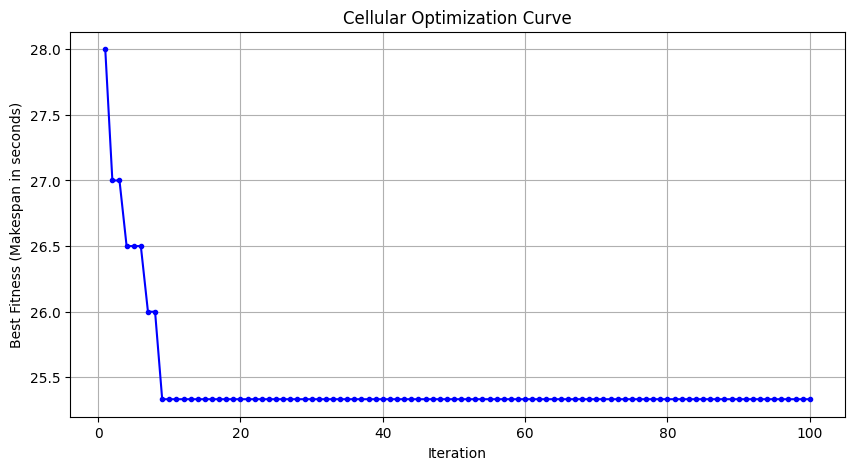

In [1]:
import numpy as np
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt

# Problem Setup: 6 Tasks to assign across 3 Cloud Servers
num_tasks = 6
num_servers = 3
task_loads = np.array([12, 25, 8, 30, 15, 20])     # Compute units needed per task
server_speeds = np.array([1.0, 1.5, 2.0])          # Processing speed of each server

# Grid Setup (4x4 Cellular Grid of candidate resource allocations)
ROWS, COLS = 4, 4
grid = np.random.randint(0, num_servers, size=(ROWS, COLS, num_tasks))

def evaluate_fitness(allocation):
    # Calculate total execution time (makespan) on the busiest server
    server_times = np.zeros(num_servers)
    for task_id, server_id in enumerate(allocation):
        server_times[server_id] += task_loads[task_id] / server_speeds[server_id]
    return np.max(server_times)  # Lower makespan = better fitness

def get_neighbors(r, c):
    # Von Neumann neighborhood (Up, Down, Left, Right with wrap-around)
    return [
        grid[(r - 1) % ROWS, c],
        grid[(r + 1) % ROWS, c],
        grid[r, (c - 1) % COLS],
        grid[r, (c + 1) % COLS]
    ]

# Tracking history for the optimization curve
best_fitness_history = []
total_iterations = 100

# Run Parallel Cellular Optimization
for iteration in range(1, total_iterations + 1):
    # Step 1: Parallel Fitness Evaluation across all cells
    flat_cells = grid.reshape(-1, num_tasks)
    with ThreadPoolExecutor() as executor:
        fitness_scores = list(executor.map(evaluate_fitness, flat_cells))
    fitness_grid = np.array(fitness_scores).reshape(ROWS, COLS)

    # Track current best fitness
    current_best_fitness = np.min(fitness_grid)
    best_fitness_history.append(current_best_fitness)

    # Print optimization progress at specific intervals
    if iteration in [10, 50, 100]:
        best_idx = np.argmin(fitness_grid)
        best_alloc = flat_cells[best_idx]
        print(f"Iteration {iteration:3d}: Best Makespan = {current_best_fitness:6.2f} sec | Assignment: {best_alloc}")

    # Step 2: Local Neighborhood Update & Mutation
    new_grid = np.copy(grid)
    for r in range(ROWS):
        for c in range(COLS):
            neighbors = get_neighbors(r, c)
            best_neighbor = min(neighbors, key=evaluate_fitness)

            # Crossover with best local neighbor
            mask = np.random.rand(num_tasks) > 0.5
            child = np.where(mask, grid[r, c], best_neighbor)

            # Small random mutation to explore new server assignments
            if np.random.rand() < 0.2:
                child[np.random.randint(num_tasks)] = np.random.randint(num_servers)

            if evaluate_fitness(child) <= fitness_grid[r, c]:
                new_grid[r, c] = child
    grid = new_grid

# Extract Best Allocation
flat_cells = grid.reshape(-1, num_tasks)
best_allocation = min(flat_cells, key=evaluate_fitness)
final_makespan = evaluate_fitness(best_allocation)

print("\n--- Final Result ---")
print("Optimal Server Assignment per Task:", best_allocation)
print("Minimized Maximum Completion Time:", round(final_makespan, 2), "sec")

# Plot the Optimization Curve
plt.figure(figsize=(10, 5))
plt.plot(range(1, total_iterations + 1), best_fitness_history, marker='o', markersize=3, color='b', linestyle='-')
plt.title("Cellular Optimization Curve")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness (Makespan in seconds)")
plt.grid(True)
plt.show()